   # EDA on Retail Sales Data
   Saqlain Akbar | Data Analytics Intern, Oasis Infobyte
   
   Dataset: Sales_transactions_2022_2025.csv

In [33]:
   import pandas as pd
   import numpy as np
   import matplotlib.pyplot as plt
   import seaborn as sns

   df = pd.read_csv("Sales_transactions_2022_2025.csv")

In [34]:
   df.shape

(18045, 36)

The dataset contains 18,045 rows and 36 columns, covering retail transactions from January 2022 to December 2025.

In [35]:
df.head()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022


The sample rows show customer segments such as Consumer, Corporate and Returning Customer, and sales channels such as Online and B2B Portal. Delivery speed varies by shipping method (Standard, Express, Next Day), and Return_Reason is NaN when an order was not returned.

I also noticed that some customers’ names don’t match their gender. Row 4 is a “Sophia Smith” recorded as Male, and the same name appears for different customer IDs. This is probably random synthetic data, so we won’t use customer names in any analysis. We’ll use Customer_ID instead.

In [36]:
   df.dtypes

,0
Transaction_ID,object
Order_ID,object
Customer_ID,object
Customer_Name,object
Customer_Age,float64
Customer_Gender,object
Customer_Segment,object
Order_Date,object
Order_Time,object
Sales_Channel,object


Most columns are text (object) or decimal numbers. Order_Date and Order_Time are stored as text and need converting to datetime. Quantity and Order_Year are integers, and the monetary columns (Unit_Price, Sales_Amount, Cost_Amount, Profit) are floats.

In [37]:
   df.isnull().sum()

,0
Transaction_ID,0
Order_ID,0
Customer_ID,0
Customer_Name,108
Customer_Age,218
Customer_Gender,162
Customer_Segment,0
Order_Date,0
Order_Time,0
Sales_Channel,0


Missing values appear in Customer_Name (108), Customer_Age (218), Customer_Gender (162), Product_Name (144), Payment_Method (147), Delivery_Days (162) and Inventory_Level (198). Return_Reason (16,168) and Promotion_Code (9,737) are mostly empty because most orders were not returned and had no promotion, so these nulls are expected. Customer_Rating has 3,435 missing values, as many customers did not leave a rating. No nulls exist in the key sales columns (Sales_Amount, Quantity, Order_Date, Product_Category).

In [38]:
print("Before:", df.shape)

# 1. Remove duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

# 2. Standardise inconsistent text (male / FEMALE / electronics / SHIPPED ...)
for col in ["Customer_Gender", "Product_Category", "Order_Status"]:
    df[col] = df[col].str.strip().str.title()
df["Customer_Gender"] = df["Customer_Gender"].replace({"Non Binary": "Non-Binary"})

# 3. Fix data types
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# 4. Remove impossible values
df = df[df["Quantity"] > 0]
df = df[df["Discount_Percentage"].between(0, 100)]
df.loc[~df["Customer_Age"].between(16, 90), "Customer_Age"] = np.nan

# 5. Fill missing values
df["Customer_Age"] = df["Customer_Age"].fillna(df["Customer_Age"].median())
df["Customer_Gender"] = df["Customer_Gender"].fillna("Unknown")
df["Product_Name"] = df["Product_Name"].fillna("Unknown")

print("Final:", df.shape)

Before: (18045, 36)
After removing duplicates: (18000, 36)
Final: (17991, 36)


Duplicates removed because a transaction should appear once.
Text standardised so “male” and “Male” are counted together.
Quantity ≤ 0 and discounts over 100% are impossible values, so those rows were removed.
Ages outside 16–90 were treated as entry errors and replaced with the median (39).
Missing gender and product names were labelled “Unknown” rather than guessed.

In [39]:
df["Customer_Gender"].value_counts()
df["Product_Category"].value_counts()

,count
Product_Category,
Electronics,8184
Office Supplies,4523
Furniture,3301
Appliances,1983


In [40]:
num_cols = ["Customer_Age","Quantity","Unit_Price","Discount_Percentage",
            "Sales_Amount","Cost_Amount","Profit"]
stats = df[num_cols].agg(["mean","median","std"]).T
stats["mode"] = [df[c].mode()[0] for c in num_cols]
stats.round(2)

,mean,median,std,mode
Customer_Age,38.92,39.00,10.63,39.00
Quantity,2.13,2.00,1.78,1.00
Unit_Price,232.71,99.81,294.22,23.82
Discount_Percentage,6.25,5.00,6.84,0.00
Sales_Amount,457.41,168.69,857.29,68.65
Cost_Amount,366.09,122.29,706.49,13.91
Profit,91.42,40.19,167.89,10.01


the mean is much higher than the median, so a few very large orders pull the average up and the data is right-skewed. The same holds for Unit_Price and Profit.

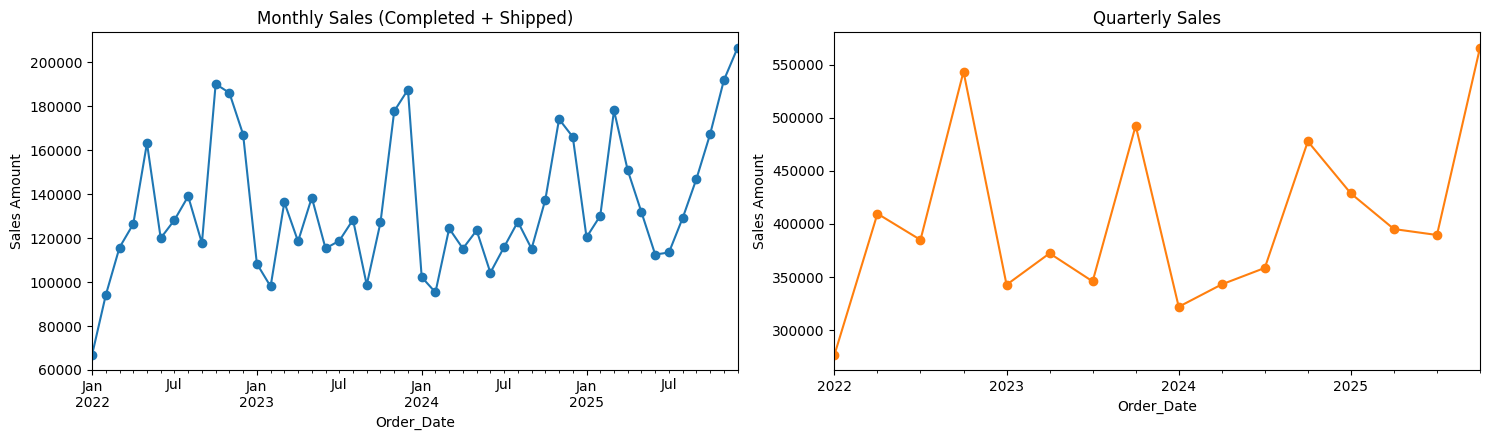

In [41]:
sales = df[df["Order_Status"].isin(["Completed", "Shipped"])].copy()

monthly   = sales.set_index("Order_Date")["Sales_Amount"].resample("ME").sum()
quarterly = sales.set_index("Order_Date")["Sales_Amount"].resample("QE").sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
monthly.plot(ax=ax[0], marker="o");   ax[0].set_title("Monthly Sales (Completed + Shipped)")
quarterly.plot(ax=ax[1], marker="o", color="tab:orange"); ax[1].set_title("Quarterly Sales")
for a in ax: a.set_ylabel("Sales Amount")
plt.tight_layout(); plt.show()

Sales show a clear seasonal pattern: Q4 (Oct–Dec) is the strongest quarter in every year, rising from about 544K in Q4 2022 to about 566K in Q4 2025, which suggests year-end shopping demand. After each Q4 peak, sales drop sharply in Q1. Overall, monthly sales trend upward, ending at about 206K in December 2025.

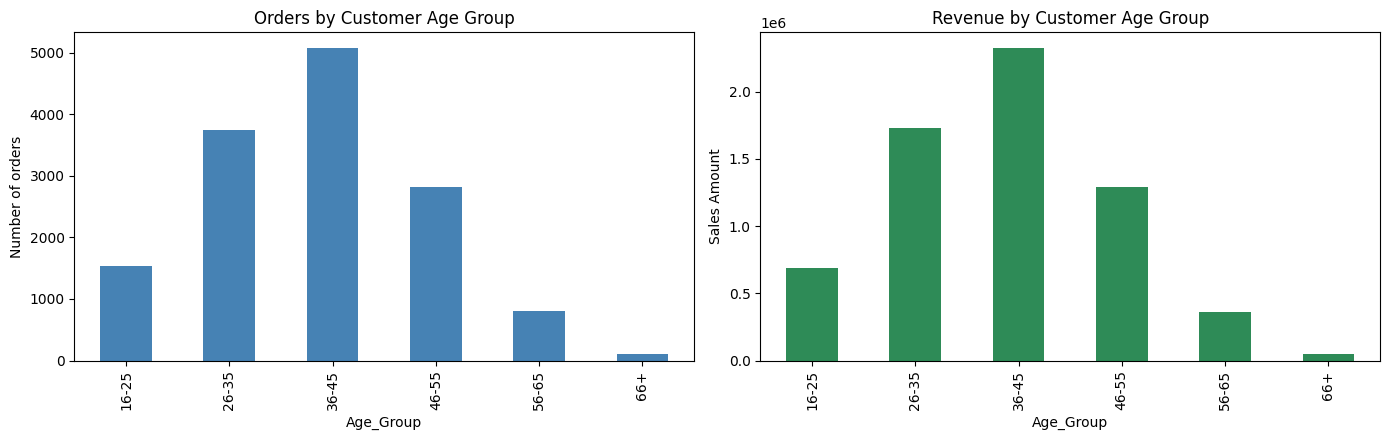

In [42]:
bins   = [15, 25, 35, 45, 55, 65, 100]
labels = ["16-25", "26-35", "36-45", "46-55", "56-65", "66+"]
sales["Age_Group"] = pd.cut(sales["Customer_Age"], bins=bins, labels=labels)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sales["Age_Group"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Orders by Customer Age Group"); ax[0].set_ylabel("Number of orders")
sales.groupby("Age_Group", observed=True)["Sales_Amount"].sum().plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("Revenue by Customer Age Group"); ax[1].set_ylabel("Sales Amount")
plt.tight_layout(); plt.show()

The 36–45 age group is the most valuable customer segment, with about 5,074 orders and roughly 2.3M in revenue, around 36% of total sales. The 26–35 and 46–55 groups follow. Together, customers aged 26–55 place the large majority of orders. Customers aged 16–25 contribute less (about 1,535 orders), and those over 65 are very rare (114 orders). Implication: marketing should focus mainly on working-age adults (26–55), while the youngest and oldest groups are an untapped opportunity.

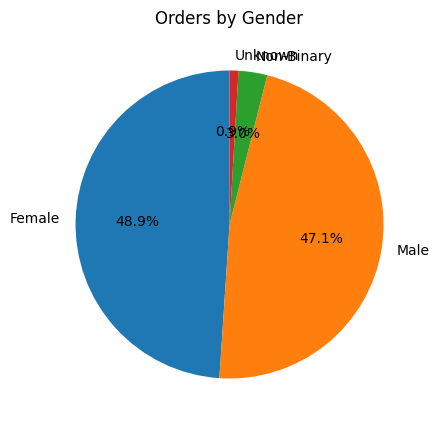

In [43]:
gender = sales["Customer_Gender"].value_counts()
gender.plot(kind="pie", autopct="%1.1f%%", figsize=(5, 5), startangle=90)
plt.title("Orders by Gender"); plt.ylabel(""); plt.show()

Orders are almost evenly split between Female (about 48.9%) and Male (about 47.1%). Non-Binary customers account for about 3.0%, and about 0.9% have no recorded gender. Implication: gender is not a strong differentiator in this business, so campaigns don’t need to target one gender. Age and product interest are better ways to segment customers.

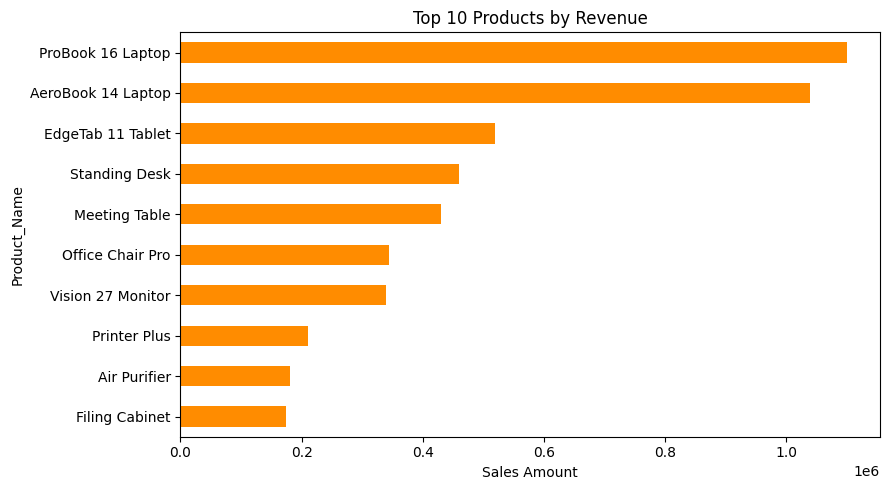

,Sales_Amount
Product_Name,
ProBook 16 Laptop,1099479.0
AeroBook 14 Laptop,1038924.0
EdgeTab 11 Tablet,519166.0
Standing Desk,460062.0
Meeting Table,429638.0
Office Chair Pro,344496.0
Vision 27 Monitor,339769.0
Printer Plus,210044.0
Air Purifier,180833.0


In [44]:
top10 = (sales[sales["Product_Name"] != "Unknown"]
         .groupby("Product_Name")["Sales_Amount"].sum()
         .sort_values(ascending=False).head(10))

plt.figure(figsize=(9, 5))
top10.sort_values().plot(kind="barh", color="darkorange")
plt.title("Top 10 Products by Revenue"); plt.xlabel("Sales Amount"); plt.tight_layout(); plt.show()
top10.round(0)

Laptops dominate revenue. The ProBook 16 Laptop (about 1.10M) and AeroBook 14 Laptop (about 1.04M) are the top two products, together generating about 2.1M. The EdgeTab 11 Tablet (about 519K) is third, followed by office furniture such as the Standing Desk, Meeting Table and Office Chair Pro. Implication: revenue depends heavily on a few high-priced products, so keeping them in stock and well promoted is critical.

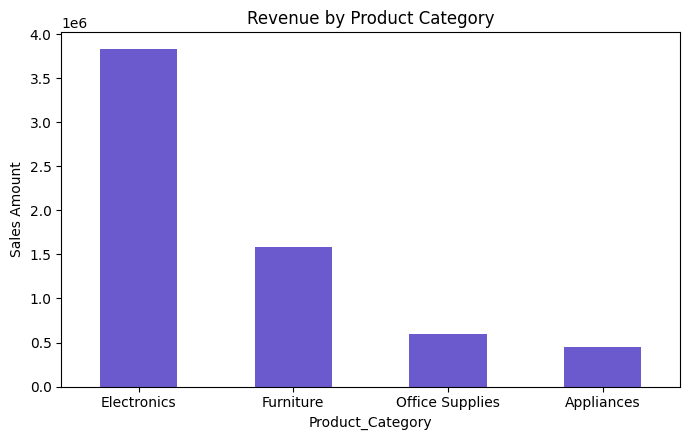

In [45]:
cat = sales.groupby("Product_Category")["Sales_Amount"].sum().sort_values(ascending=False)
cat.plot(kind="bar", color="slateblue", figsize=(7, 4.5))
plt.title("Revenue by Product Category"); plt.ylabel("Sales Amount"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

Electronics is by far the largest category, with about 3.83M in revenue (roughly 59% of total sales). Furniture comes second (about 1.58M), while Office Supplies (about 596K) and Appliances (about 446K) contribute much less. Implication: the business relies heavily on a single category. Growing Furniture and Appliances would reduce this risk and make revenue more balanced.

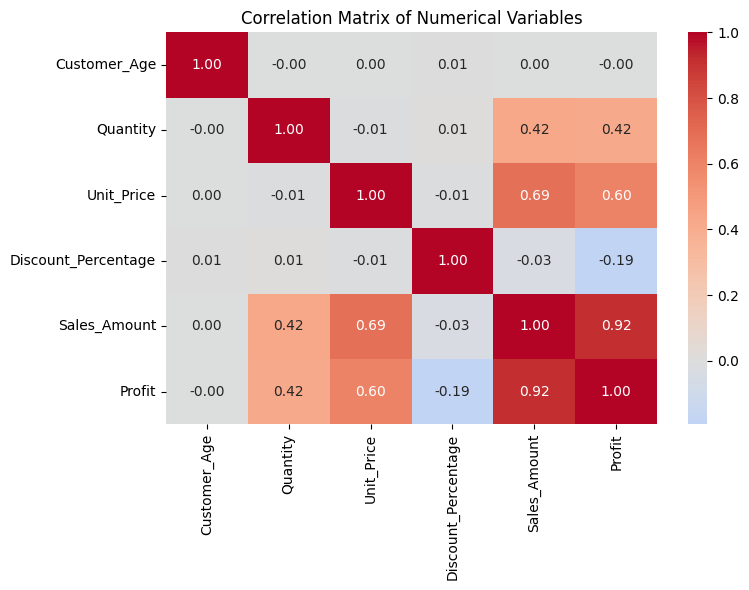

In [46]:
corr_cols = ["Customer_Age","Quantity","Unit_Price","Discount_Percentage","Sales_Amount","Profit"]
plt.figure(figsize=(8, 6))
sns.heatmap(sales[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Variables"); plt.tight_layout(); plt.show()

Sales_Amount is strongly linked to Unit_Price (0.69) and moderately to Quantity (0.42), so both price and volume drive revenue, with price mattering more. Profit moves almost together with Sales_Amount (0.92). Discount_Percentage has a negative correlation with Profit (−0.19), meaning heavier discounts reduce profit. Customer_Age shows no relationship with any variable (about 0), so age does not affect how much a customer spends.

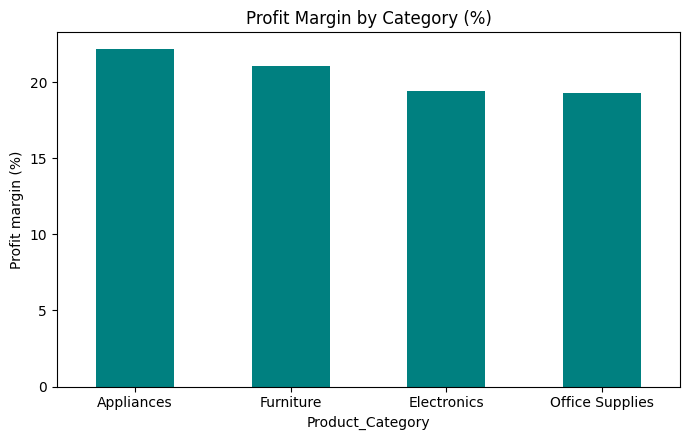

,Sales_Amount,Profit,Profit_Margin_%
Product_Category,,,
Appliances,445714.0,98789.4,22.2
Electronics,3827585.0,742631.8,19.4
Furniture,1580720.1,332807.8,21.1
Office Supplies,595511.9,115029.9,19.3


In [47]:
g = sales.groupby("Product_Category")[["Sales_Amount", "Profit"]].sum()
g["Profit_Margin_%"] = g["Profit"] / g["Sales_Amount"] * 100
g["Profit_Margin_%"].sort_values(ascending=False).plot(kind="bar", color="teal", figsize=(7, 4.5))
plt.title("Profit Margin by Category (%)"); plt.ylabel("Profit margin (%)"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
g.round(1)

Electronics earns the most revenue but has one of the lowest profit margins (about 19.4%). Appliances (about 22.2%) and Furniture (about 21.1%) are more profitable per sale, even though they bring in far less revenue. Implication: the biggest category is not the most efficient one, so growing Furniture and Appliances could raise overall profit.

## Conclusion and Business Recommendations

1. **Prepare for Q4 every year.** Q4 (Oct–Dec) is the strongest quarter in all four years; Q4 2025 sales were about 45% higher than Q3 2025. Stock up on inventory and run promotions before October.
2. **Focus marketing on customers aged 26–55, especially 36–45.** This group generates the most orders and about 36% of total revenue, while age has no link to spending per order, so reaching more of these customers is the best way to grow.
3. **Reduce dependence on Electronics (about 59% of revenue).** Furniture and Appliances have higher profit margins (21–22% vs 19%), so growing them would make revenue more balanced and profitable. Also review heavy discounting, which lowers profit.